<a href="https://colab.research.google.com/github/Hadeel-93/Final-Project/blob/main/CNN_LSTMipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PTB-XL CNN-LSTM BINARY CLASSIFICATION
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB

Searching for locally extracted dataset...
Searching for ZIP file in Google Drive...
ZIP file found: /content/drive/MyDrive/ptb-xl-1.0.3.zip
ZIP size: 1.71 GB

Copying ZIP to Colab local storage...
Copy completed in 67.71 seconds.

Extracting required dataset files...


Extracting PTB-XL:   0%|          | 0/43600 [00:00<?, ?it/s]


Extraction completed in 12.39 seconds.

DATASET SUCCESSFULLY LOCATED
Dataset directory: /content/PTBXL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Output directory: /content/drive/MyDrive/ECGR5105_CNN_LSTM_Corrected
Metadata: True
SCP statements: True
100-Hz recordings: True
Number of ECG data files: 21799

Original dataset size: 21799

Available metadata columns:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']

Label distribution before filtering:
binary_label
1.0    12319
0.0     9069
NaN      411
Name: count, dtype: int64

CORRECTED DATASET DISTRIBUTION
Original recordings: 21,799
Excluded recordings: 41

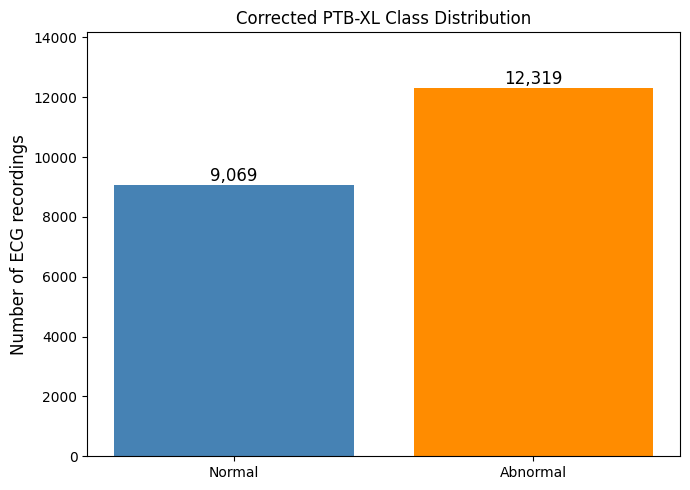


Dataset partitions:
   Dataset  Total  Normal  Abnormal  Normal (%)  Abnormal (%)
  Training  17084    7243      9841       42.40         57.60
Validation   2146     914      1232       42.59         57.41
      Test   2158     912      1246       42.26         57.74

Patient-level data leakage check: PASSED

Loading Training ECG signals...


Training:   0%|          | 0/17084 [00:00<?, ?it/s]


Loading Validation ECG signals...


Validation:   0%|          | 0/2146 [00:00<?, ?it/s]


Loading Test ECG signals...


Test:   0%|          | 0/2158 [00:00<?, ?it/s]

... (43 outputs left out)

Training:   0%|          | 0/134 [00:00<?, ?it/s]

Epoch 22/50 | Train Loss: 0.2313 | Train Acc: 90.00% | Val Loss: 0.3513 | Val Acc: 86.67% | Val AUC: 0.9366 | Time: 3.90s
  Early stopping counter: 7/8


Training:   0%|          | 0/134 [00:00<?, ?it/s]

Epoch 23/50 | Train Loss: 0.2345 | Train Acc: 90.10% | Val Loss: 0.3406 | Val Acc: 86.49% | Val AUC: 0.9349 | Time: 2.86s
  Early stopping counter: 8/8

Early stopping triggered at epoch 23.

TRAINING COMPLETED
Epochs completed: 23
Best epoch: 15
Best validation loss: 0.320198
Training time: 76.03 seconds
Training time: 1.27 minutes

Evaluating best model on the test set...

FINAL CNN-LSTM TEST RESULTS
Test Loss:         0.342404
Accuracy:          84.94%
Balanced Accuracy: 85.67%
Precision:         91.98%
Sensitivity:       80.98%
Specificity:       90.35%
F1-score:          86.13%
Macro F1-score:    84.83%
Weighted F1-score: 85.03%
ROC-AUC:           0.9268
Average Precision: 0.9529
Majority Baseline: 57.74%
Testing Time:      0.31 seconds

Confusion Matrix:
[[ 824   88]
 [ 237 1009]]

True Negatives:  824
False Positives: 88
False Negatives: 237
True Positives:  1009

Classification Report:
              precision    recall  f1-score   support

      Normal     0.7766    0.9035    0

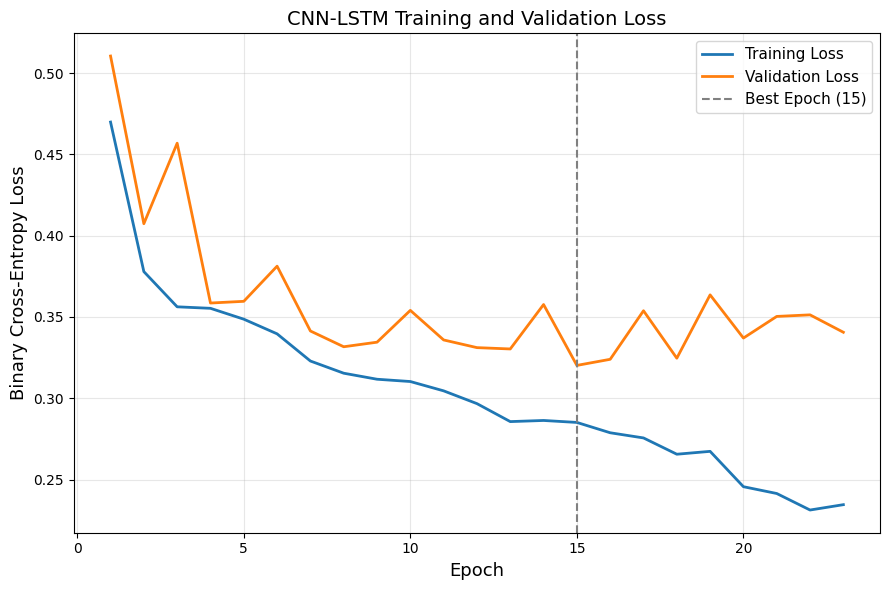

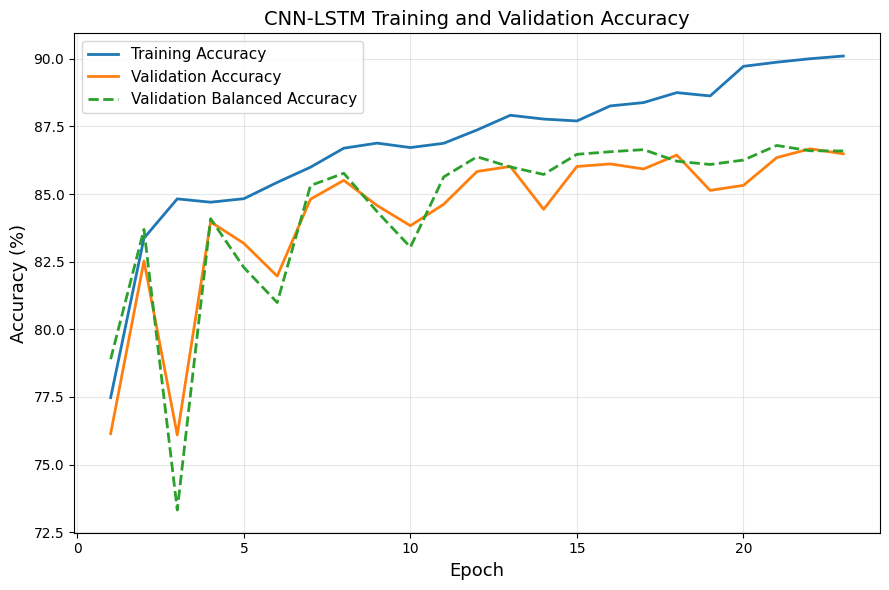

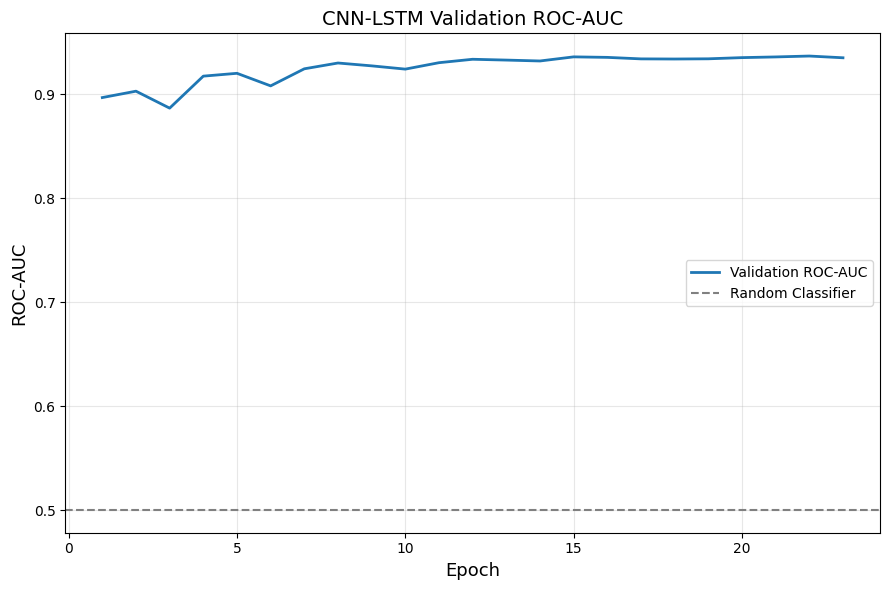

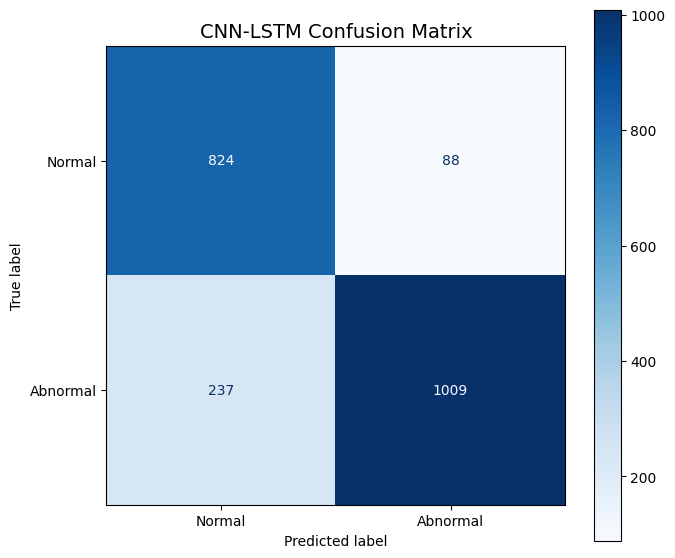

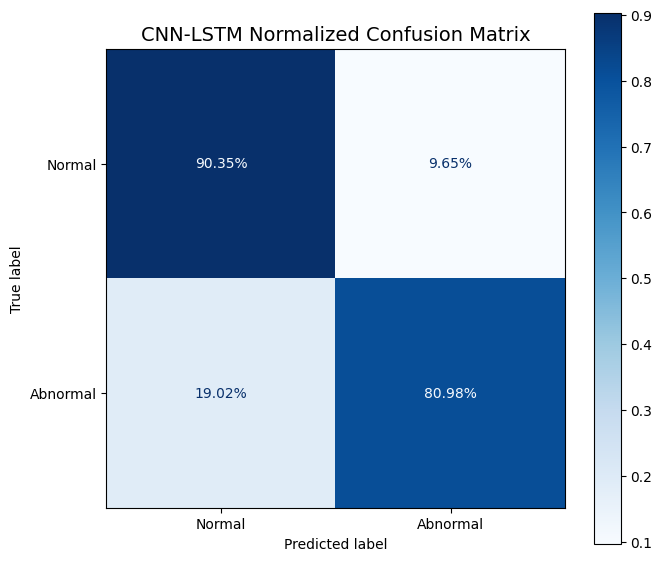

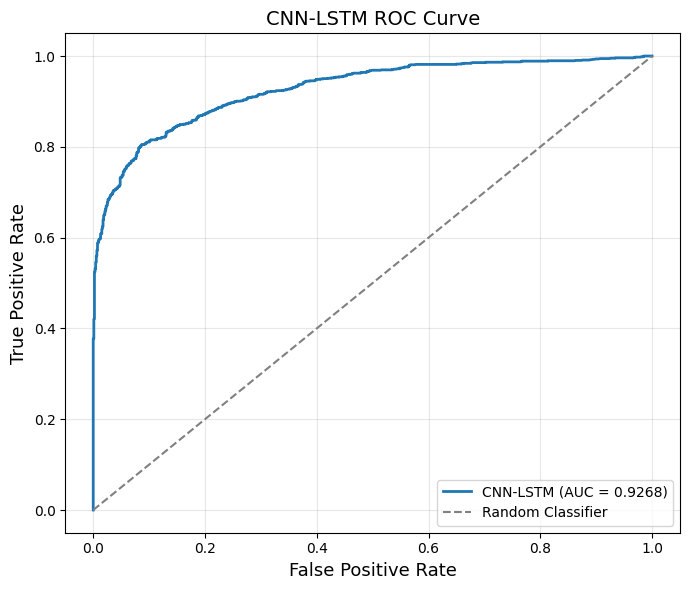

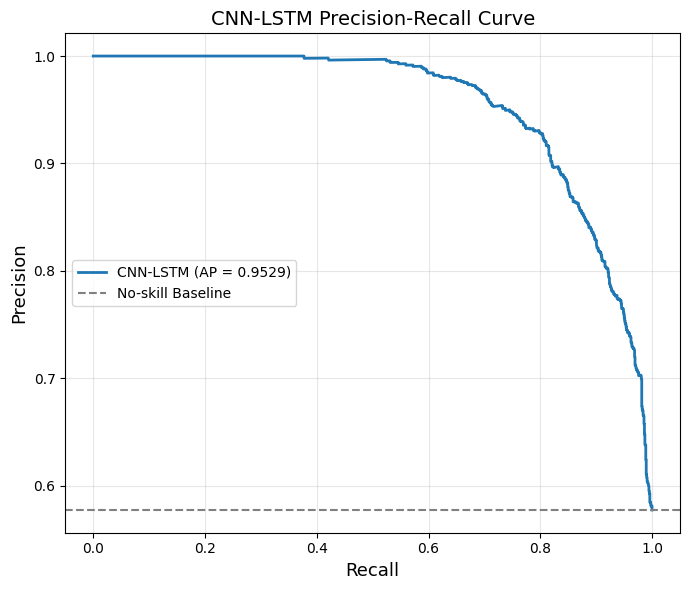

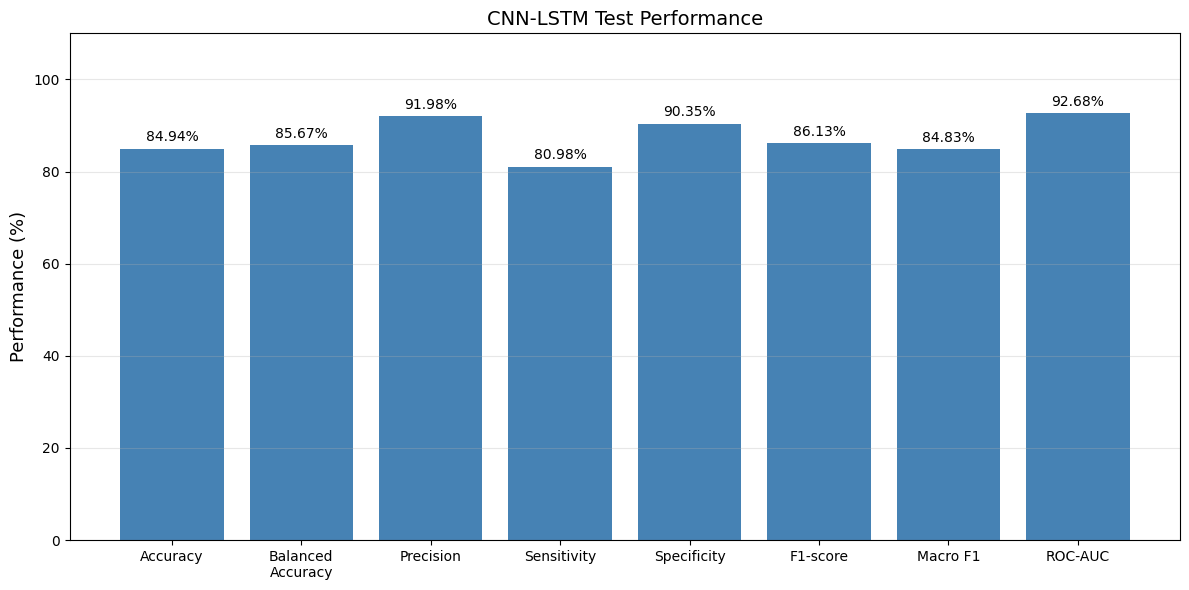


FINAL EXPERIMENT SUMMARY
                      Metric        Value
                       Model     CNN-LSTM
             Dataset Version PTB-XL 1.0.3
       Original Dataset Size        21799
         Usable Dataset Size        21388
              Normal Samples         9069
            Abnormal Samples        12319
            Excluded Samples          411
            Training Samples        17084
          Validation Samples         2146
                Test Samples         2158
            Input Dimensions    12 x 1000
                  CNN Blocks            3
                 LSTM Layers            2
            LSTM Hidden Size          128
            Total Parameters       484033
         Parameter Size (MB)       1.8464
       Saved Model Size (MB)       1.8595
              Maximum Epochs           50
            Epochs Completed           23
                  Best Epoch           15
                  Batch Size          128
                         GPU     Tesla T4
Preproce

In [ ]:
# ============================================================
# PTB-XL ECG BINARY CLASSIFICATION
# HYBRID CNN-LSTM MODEL
# Corrected Implementation
# Google Colab + Tesla T4 GPU
# ============================================================

!pip -q install wfdb

import os
import ast
import time
import random
import json
import zipfile
import shutil

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    average_precision_score,
    precision_recall_curve
)

from tqdm.auto import tqdm
from google.colab import drive


# ============================================================
# 1. CONFIGURATION
# ============================================================

drive.mount('/content/drive')

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 50
PATIENCE = 8
LEARNING_RATE = 0.001
MIN_DELTA = 1e-5
NUM_WORKERS = 2

SEARCH_ROOT = Path('/content/drive/MyDrive')

EXTRACT_DIR = Path('/content/PTBXL')

OUTPUT_DIR = Path(
    '/content/drive/MyDrive/ECGR5105_CNN_LSTM_Corrected'
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

USE_AMP = DEVICE.type == 'cuda'

print("=" * 70)
print("PTB-XL CNN-LSTM BINARY CLASSIFICATION")
print("=" * 70)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU Memory: {gpu_memory:.2f} GB")

    torch.backends.cudnn.benchmark = True

else:

    raise RuntimeError(
        "GPU is not enabled. Go to Runtime -> "
        "Change runtime type -> T4 GPU."
    )


# ============================================================
# 2. AUTOMATIC DATASET DETECTION AND EXTRACTION
# ============================================================

def find_dataset(root):

    for metadata_path in root.rglob('ptbxl_database.csv'):

        candidate = metadata_path.parent

        if (
            (candidate / 'scp_statements.csv').exists()
            and
            (candidate / 'records100').exists()
        ):

            return candidate

    return None


print("\nSearching for locally extracted dataset...")

DATA_DIR = find_dataset(EXTRACT_DIR)

if DATA_DIR is None:

    print("Searching for ZIP file in Google Drive...")

    zip_files = list(
        SEARCH_ROOT.rglob('ptb-xl-1.0.3.zip')
    )

    # Alternative search if the file has a slightly
    # different name.

    if not zip_files:

        zip_files = list(
            SEARCH_ROOT.rglob('*ptb-xl*.zip')
        )

    if zip_files:

        ZIP_PATH = zip_files[0]

        print("ZIP file found:", ZIP_PATH)

        LOCAL_ZIP = Path('/content/ptb-xl-1.0.3.zip')

        print(
            f"ZIP size: "
            f"{ZIP_PATH.stat().st_size / (1024**3):.2f} GB"
        )

        # Copy ZIP to local Colab storage.

        copy_start = time.perf_counter()

        if (
            not LOCAL_ZIP.exists()
            or
            LOCAL_ZIP.stat().st_size
            != ZIP_PATH.stat().st_size
        ):

            print("\nCopying ZIP to Colab local storage...")

            shutil.copy2(
                ZIP_PATH,
                LOCAL_ZIP
            )

        print(
            f"Copy completed in "
            f"{time.perf_counter() - copy_start:.2f} seconds."
        )

        # Extract metadata and 100-Hz ECG recordings only.
        # The 500-Hz recordings are not required.

        print("\nExtracting required dataset files...")

        extraction_start = time.perf_counter()

        with zipfile.ZipFile(LOCAL_ZIP, 'r') as zip_ref:

            members = [

                member

                for member in zip_ref.infolist()

                if (

                    'records100/' in member.filename

                    or member.filename.endswith(
                        'ptbxl_database.csv'
                    )

                    or member.filename.endswith(
                        'scp_statements.csv'
                    )

                )

            ]

            if not members:

                raise RuntimeError(
                    "Required PTB-XL files were not found "
                    "inside the ZIP archive."
                )

            for member in tqdm(

                members,

                desc='Extracting PTB-XL'

            ):

                zip_ref.extract(
                    member,
                    EXTRACT_DIR
                )

        extraction_time = (
            time.perf_counter() - extraction_start
        )

        print(
            f"\nExtraction completed in "
            f"{extraction_time:.2f} seconds."
        )

        DATA_DIR = find_dataset(EXTRACT_DIR)

    else:

        print("ZIP not found. Searching extracted Drive files...")

        DATA_DIR = find_dataset(SEARCH_ROOT)


if DATA_DIR is None:

    raise FileNotFoundError(
        "PTB-XL dataset could not be located. "
        "Verify that ptb-xl-1.0.3.zip is in MyDrive."
    )


print("\n" + "=" * 70)
print("DATASET SUCCESSFULLY LOCATED")
print("=" * 70)

print("Dataset directory:", DATA_DIR)

print("Output directory:", OUTPUT_DIR)

print(
    "Metadata:",
    (DATA_DIR / 'ptbxl_database.csv').exists()
)

print(
    "SCP statements:",
    (DATA_DIR / 'scp_statements.csv').exists()
)

print(
    "100-Hz recordings:",
    (DATA_DIR / 'records100').exists()
)

data_file_count = len(

    list(
        (DATA_DIR / 'records100').rglob('*.dat')
    )

)

print(
    "Number of ECG data files:",
    data_file_count
)


# ============================================================
# 3. LOAD DATASET METADATA
# ============================================================

metadata = pd.read_csv(

    DATA_DIR / 'ptbxl_database.csv',

    index_col='ecg_id'

)

scp_statements = pd.read_csv(

    DATA_DIR / 'scp_statements.csv',

    index_col=0

)

metadata['scp_codes'] = (

    metadata['scp_codes'].apply(
        ast.literal_eval
    )

)

original_dataset_size = len(metadata)

print("\nOriginal dataset size:", original_dataset_size)

print("\nAvailable metadata columns:")

print(metadata.columns.tolist())


# ============================================================
# 4. CORRECTED BINARY LABEL GENERATION
# ============================================================

# Binary classification:
#
# Normal = 0
# Abnormal = 1
#
# Diagnostic superclasses:
#
# NORM: Normal ECG
# MI:   Myocardial Infarction
# STTC: ST/T Change
# CD:   Conduction Disturbance
# HYP:  Hypertrophy
#
# Labeling rules:
#
# 1. Only NORM -> Normal
# 2. Any abnormal diagnostic superclass -> Abnormal
# 3. No identifiable diagnostic superclass -> Excluded
#
# Abnormal diagnostic labels take priority when
# both normal and abnormal labels are present.


diagnostic_statements = scp_statements[

    scp_statements['diagnostic'] == 1

]

diagnostic_mapping = (

    diagnostic_statements['diagnostic_class']

    .dropna()

    .to_dict()

)

ABNORMAL_CLASSES = {

    'MI',

    'STTC',

    'CD',

    'HYP'

}


def extract_diagnostic_classes(scp_codes):

    classes = set()

    for code in scp_codes.keys():

        if code in diagnostic_mapping:

            classes.add(

                diagnostic_mapping[code]

            )

    return sorted(classes)


def create_binary_label(classes):

    classes = set(classes)

    if classes.intersection(ABNORMAL_CLASSES):

        return 1

    elif classes == {'NORM'}:

        return 0

    else:

        return np.nan


metadata['diagnostic_classes'] = (

    metadata['scp_codes']

    .apply(extract_diagnostic_classes)

)

metadata['binary_label'] = (

    metadata['diagnostic_classes']

    .apply(create_binary_label)

)

print("\nLabel distribution before filtering:")

print(

    metadata['binary_label']

    .value_counts(dropna=False)

)

excluded_count = int(

    metadata['binary_label'].isna().sum()

)

metadata = metadata.dropna(

    subset=['binary_label']

).copy()

metadata['binary_label'] = (

    metadata['binary_label'].astype(int)

)

normal_count = int(

    (metadata['binary_label'] == 0).sum()

)

abnormal_count = int(

    (metadata['binary_label'] == 1).sum()

)

total_count = len(metadata)

normal_percentage = (

    100 * normal_count / total_count

)

abnormal_percentage = (

    100 * abnormal_count / total_count

)

print("\n" + "=" * 70)
print("CORRECTED DATASET DISTRIBUTION")
print("=" * 70)

print(f"Original recordings: {original_dataset_size:,}")

print(f"Excluded recordings: {excluded_count:,}")

print(f"Usable recordings:   {total_count:,}")

print(

    f"Normal recordings:   {normal_count:,} "

    f"({normal_percentage:.2f}%)"

)

print(

    f"Abnormal recordings: {abnormal_count:,} "

    f"({abnormal_percentage:.2f}%)"

)

print("\nPrevious Random Forest reference:")

print("Normal:   9,069")

print("Abnormal: 12,319")

print("Excluded: 411")

print("Usable:   21,388")

if normal_count == 9069 and abnormal_count == 12319:

    print("\nClass counts match Random Forest.")

else:

    print("\nWARNING: Class counts differ from Random Forest.")

    print(

        "Verify that all project models use the same "

        "labeling procedure and dataset version."

    )

# Prevent training on the severely imbalanced
# dataset encountered in the original implementation.

assert 0.20 < normal_count / total_count < 0.80, (

    "Unexpected class imbalance. "

    "Inspect the labeling procedure before training."

)

metadata.to_csv(

    OUTPUT_DIR / 'corrected_metadata.csv'

)


# ============================================================
# 5. DATASET DISTRIBUTION PLOT
# ============================================================

plt.figure(figsize=(7, 5))

bars = plt.bar(

    ['Normal', 'Abnormal'],

    [normal_count, abnormal_count],

    color=['steelblue', 'darkorange']

)

for bar, count in zip(

    bars,

    [normal_count, abnormal_count]

):

    plt.text(

        bar.get_x() + bar.get_width() / 2,

        bar.get_height(),

        f'{count:,}',

        ha='center',

        va='bottom',

        fontsize=12

    )

plt.ylabel('Number of ECG recordings', fontsize=12)

plt.title('Corrected PTB-XL Class Distribution')

plt.ylim(0, max(normal_count, abnormal_count) * 1.15)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'class_distribution.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 6. OFFICIAL PTB-XL DATASET PARTITIONS
# ============================================================

# Training:   Folds 1-8
# Validation: Fold 9
# Testing:    Fold 10

train_df = metadata[

    metadata['strat_fold'].between(1, 8)

].copy()

val_df = metadata[

    metadata['strat_fold'] == 9

].copy()

test_df = metadata[

    metadata['strat_fold'] == 10

].copy()


def describe_split(name, df):

    normal = int(

        (df['binary_label'] == 0).sum()

    )

    abnormal = int(

        (df['binary_label'] == 1).sum()

    )

    total = len(df)

    return {

        'Dataset': name,

        'Total': total,

        'Normal': normal,

        'Abnormal': abnormal,

        'Normal (%)': round(
            100 * normal / total, 2
        ),

        'Abnormal (%)': round(
            100 * abnormal / total, 2
        )

    }


split_summary = pd.DataFrame([

    describe_split('Training', train_df),

    describe_split('Validation', val_df),

    describe_split('Test', test_df)

])

print("\nDataset partitions:")

print(

    split_summary.to_string(index=False)

)

split_summary.to_csv(

    OUTPUT_DIR / 'dataset_distribution.csv',

    index=False

)

assert (

    len(train_df) + len(val_df) + len(test_df)

    == len(metadata)

)

# Ensure that both classes exist in every partition.

for name, df in [

    ('Training', train_df),

    ('Validation', val_df),

    ('Test', test_df)

]:

    assert df['binary_label'].nunique() == 2, (

        f"{name} partition does not contain both classes."

    )


# ============================================================
# 7. PATIENT-LEVEL DATA LEAKAGE CHECK
# ============================================================

train_patients = set(train_df['patient_id'])

val_patients = set(val_df['patient_id'])

test_patients = set(test_df['patient_id'])

assert not train_patients.intersection(val_patients)

assert not train_patients.intersection(test_patients)

assert not val_patients.intersection(test_patients)

print("\nPatient-level data leakage check: PASSED")

# Save exact recording IDs and labels.

for name, df in [

    ('train', train_df),

    ('validation', val_df),

    ('test', test_df)

]:

    df[

        [

            'patient_id',

            'strat_fold',

            'binary_label'

        ]

    ].to_csv(

        OUTPUT_DIR / f'{name}_record_ids.csv'

    )


# ============================================================
# 8. ECG LOADING AND PREPROCESSING
# ============================================================

# Original ECG dimensions: (1000, 12)
# Neural network input:    (12, 1000)
#
# Each recording contains 12 leads and
# 1000 time samples at 100 Hz.
#
# Each lead is independently standardized:
#
# x_normalized = (x - mean) / standard_deviation
#
# All recordings are loaded into RAM to prevent
# repeated disk reads during training.


def load_ecg_signals(df, split_name):

    n = len(df)

    X = np.empty(

        (n, 12, 1000),

        dtype=np.float32

    )

    y = df['binary_label'].to_numpy(

        dtype=np.float32

    )

    print(f"\nLoading {split_name} ECG signals...")

    for i, filename in enumerate(

        tqdm(

            df['filename_lr'],

            total=n,

            desc=split_name

        )

    ):

        signal_path = str(

            DATA_DIR / filename

        )

        signal, fields = wfdb.rdsamp(

            signal_path

        )

        signal = np.asarray(

            signal,

            dtype=np.float32

        )

        if signal.shape != (1000, 12):

            raise ValueError(

                f"Unexpected ECG shape "

                f"{signal.shape} for {filename}"

            )

        if not np.isfinite(signal).all():

            raise ValueError(

                f"Non-finite ECG values in {filename}"

            )

        # Transpose to channels-first format.

        signal = signal.T

        # Normalize each lead independently.

        mean = signal.mean(

            axis=1,

            keepdims=True

        )

        std = signal.std(

            axis=1,

            keepdims=True

        )

        signal = (

            (signal - mean)

            / np.maximum(std, 1e-8)

        )

        X[i] = signal

    return X, y


preprocessing_start = time.perf_counter()

X_train, y_train = load_ecg_signals(

    train_df,

    'Training'

)

X_val, y_val = load_ecg_signals(

    val_df,

    'Validation'

)

X_test, y_test = load_ecg_signals(

    test_df,

    'Test'

)

preprocessing_time = (

    time.perf_counter() - preprocessing_start

)

print("\n" + "=" * 70)
print("PREPROCESSING COMPLETED")
print("=" * 70)

print("Training shape:  ", X_train.shape)

print("Validation shape:", X_val.shape)

print("Test shape:      ", X_test.shape)

print(

    f"Preprocessing time: "

    f"{preprocessing_time:.2f} seconds"

)

memory_usage_gb = (

    X_train.nbytes

    + X_val.nbytes

    + X_test.nbytes

) / (1024 ** 3)

print(

    f"ECG tensor memory usage: "

    f"{memory_usage_gb:.2f} GB"

)


# ============================================================
# 9. PYTORCH DATASET
# ============================================================

class ECGDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.from_numpy(X)

        self.y = torch.from_numpy(y)

    def __len__(self):

        return len(self.y)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


train_dataset = ECGDataset(

    X_train,

    y_train

)

val_dataset = ECGDataset(

    X_val,

    y_val

)

test_dataset = ECGDataset(

    X_test,

    y_test

)


# ============================================================
# 10. DATALOADERS
# ============================================================

loader_config = {

    'batch_size': BATCH_SIZE,

    'num_workers': NUM_WORKERS,

    'pin_memory': USE_AMP,

    'persistent_workers': NUM_WORKERS > 0

}

train_loader = DataLoader(

    train_dataset,

    shuffle=True,

    **loader_config

)

val_loader = DataLoader(

    val_dataset,

    shuffle=False,

    **loader_config

)

test_loader = DataLoader(

    test_dataset,

    shuffle=False,

    **loader_config

)

print("\nBatch size:", BATCH_SIZE)

print("Training batches:", len(train_loader))

print("Validation batches:", len(val_loader))

print("Testing batches:", len(test_loader))


# ============================================================
# 11. HYBRID CNN-LSTM ARCHITECTURE
# ============================================================

# Architecture:
#
# Input: 12 x 1000
#
# CNN Block 1: 64 x 500
# CNN Block 2: 128 x 250
# CNN Block 3: 256 x 125
#
# Transpose: 125 x 256
#
# LSTM: 2 layers, hidden size 128
#
# Fully connected: 128 -> 64 -> 1
#
# Output: Binary classification logit


class CNNLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        # CNN BLOCK 1

        self.conv1 = nn.Sequential(

            nn.Conv1d(

                in_channels=12,

                out_channels=64,

                kernel_size=7,

                padding=3

            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.MaxPool1d(

                kernel_size=2,

                stride=2

            )

        )

        # CNN BLOCK 2

        self.conv2 = nn.Sequential(

            nn.Conv1d(

                in_channels=64,

                out_channels=128,

                kernel_size=5,

                padding=2

            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.MaxPool1d(

                kernel_size=2,

                stride=2

            )

        )

        # CNN BLOCK 3

        self.conv3 = nn.Sequential(

            nn.Conv1d(

                in_channels=128,

                out_channels=256,

                kernel_size=3,

                padding=1

            ),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.MaxPool1d(

                kernel_size=2,

                stride=2

            )

        )

        # TWO-LAYER LSTM

        self.lstm = nn.LSTM(

            input_size=256,

            hidden_size=128,

            num_layers=2,

            batch_first=True,

            dropout=0.3

        )

        # FULLY CONNECTED CLASSIFIER

        self.classifier = nn.Sequential(

            nn.Linear(128, 64),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(64, 1)

        )


    def forward(self, x):

        x = self.conv1(x)

        x = self.conv2(x)

        x = self.conv3(x)

        # CNN output: (batch, 256, 125)
        # LSTM input: (batch, 125, 256)

        x = x.transpose(1, 2).contiguous()

        x, _ = self.lstm(x)

        # Select the final temporal representation.

        x = x[:, -1, :]

        x = self.classifier(x)

        return x.squeeze(-1)


model = CNNLSTM().to(DEVICE)

print("\n" + "=" * 70)
print("CNN-LSTM MODEL ARCHITECTURE")
print("=" * 70)

print(model)

total_parameters = sum(

    p.numel()

    for p in model.parameters()

)

trainable_parameters = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad

)

parameter_size_mb = sum(

    p.numel() * p.element_size()

    for p in model.parameters()

) / (1024 ** 2)

print(

    f"\nTotal parameters: "

    f"{total_parameters:,}"

)

print(

    f"Trainable parameters: "

    f"{trainable_parameters:,}"

)

print(

    f"Parameter memory size: "

    f"{parameter_size_mb:.4f} MB"

)


# ============================================================
# 12. MODEL DIMENSION VERIFICATION
# ============================================================

model.eval()

with torch.no_grad():

    dummy_input = torch.randn(

        4, 12, 1000,

        device=DEVICE

    )

    dummy_output = model(dummy_input)

assert dummy_output.shape == (4,)

print("\nArchitecture dimension check: PASSED")

del dummy_input
del dummy_output

torch.cuda.empty_cache()


# ============================================================
# 13. LOSS FUNCTION, OPTIMIZER AND SCHEDULER
# ============================================================

# Standard binary cross-entropy is used because
# the corrected dataset is reasonably balanced.

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(

    model.parameters(),

    lr=LEARNING_RATE

)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode='min',

    factor=0.5,

    patience=3,

    min_lr=1e-6

)

# Mixed-precision training for faster GPU computation.

scaler = torch.amp.GradScaler(

    'cuda',

    enabled=USE_AMP

)

print("\nOptimizer: Adam")

print("Loss: Binary Cross-Entropy with Logits")

print("Learning rate:", LEARNING_RATE)

print("Maximum epochs:", MAX_EPOCHS)

print("Early stopping patience:", PATIENCE)

print("Mixed precision:", USE_AMP)


# ============================================================
# 14. TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0

    progress_bar = tqdm(

        loader,

        desc='Training',

        leave=False

    )

    for X_batch, y_batch in progress_bar:

        X_batch = X_batch.to(

            DEVICE,

            non_blocking=True

        )

        y_batch = y_batch.to(

            DEVICE,

            non_blocking=True

        )

        optimizer.zero_grad(

            set_to_none=True

        )

        # Mixed-precision forward pass.

        with torch.autocast(

            device_type='cuda',

            dtype=torch.float16,

            enabled=USE_AMP

        ):

            logits = model(X_batch)

            loss = criterion(

                logits,

                y_batch

            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        # Prevent excessively large gradients.

        nn.utils.clip_grad_norm_(

            model.parameters(),

            max_norm=5.0

        )

        scaler.step(optimizer)

        scaler.update()

        batch_size = y_batch.size(0)

        running_loss += (

            loss.item() * batch_size

        )

        predictions = (

            logits.detach() >= 0

        ).long()

        correct += (

            predictions == y_batch.long()

        ).sum().item()

        total += batch_size

        progress_bar.set_postfix({

            'loss': f'{running_loss / total:.4f}',

            'acc': f'{100 * correct / total:.2f}%'

        })

    return (

        running_loss / total,

        correct / total

    )


# ============================================================
# 15. VALIDATION AND TESTING FUNCTION
# ============================================================

@torch.no_grad()

def evaluate(model, loader):

    model.eval()

    running_loss = 0.0

    total = 0

    all_labels = []

    all_probabilities = []

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(

            DEVICE,

            non_blocking=True

        )

        y_batch = y_batch.to(

            DEVICE,

            non_blocking=True

        )

        with torch.autocast(

            device_type='cuda',

            dtype=torch.float16,

            enabled=USE_AMP

        ):

            logits = model(X_batch)

            loss = criterion(

                logits,

                y_batch

            )

        probabilities = torch.sigmoid(

            logits.float()

        )

        running_loss += (

            loss.item() * y_batch.size(0)

        )

        total += y_batch.size(0)

        all_labels.extend(

            y_batch.cpu().numpy()

        )

        all_probabilities.extend(

            probabilities.cpu().numpy()

        )

    labels = np.asarray(

        all_labels,

        dtype=int

    )

    probabilities = np.asarray(

        all_probabilities

    )

    predictions = (

        probabilities >= 0.5

    ).astype(int)

    return {

        'loss': running_loss / total,

        'accuracy': accuracy_score(

            labels,

            predictions

        ),

        'balanced_accuracy': balanced_accuracy_score(

            labels,

            predictions

        ),

        'auc': roc_auc_score(

            labels,

            probabilities

        ),

        'labels': labels,

        'probabilities': probabilities,

        'predictions': predictions

    }


# ============================================================
# 16. TRAINING WITH EARLY STOPPING
# ============================================================

history = []

best_val_loss = float('inf')

best_epoch = 0

epochs_without_improvement = 0

early_stop_reference = float('inf')

torch.cuda.synchronize()

training_start = time.perf_counter()

print("\n" + "=" * 100)
print("STARTING CNN-LSTM TRAINING")
print("=" * 100)

for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.perf_counter()

    # Training

    train_loss, train_acc = train_one_epoch(

        model,

        train_loader

    )

    # Validation

    val_result = evaluate(

        model,

        val_loader

    )

    val_loss = val_result['loss']

    val_acc = val_result['accuracy']

    val_auc = val_result['auc']

    val_bal_acc = val_result[

        'balanced_accuracy'

    ]

    current_lr = optimizer.param_groups[0]['lr']

    scheduler.step(val_loss)

    torch.cuda.synchronize()

    epoch_time = (

        time.perf_counter() - epoch_start

    )

    # Save epoch history.

    history.append({

        'Epoch': epoch,

        'Training Loss': train_loss,

        'Training Accuracy': train_acc,

        'Validation Loss': val_loss,

        'Validation Accuracy': val_acc,

        'Validation Balanced Accuracy': val_bal_acc,

        'Validation ROC-AUC': val_auc,

        'Learning Rate': current_lr,

        'Epoch Time (s)': epoch_time

    })

    print(

        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Train Acc: {100 * train_acc:.2f}% | "

        f"Val Loss: {val_loss:.4f} | "

        f"Val Acc: {100 * val_acc:.2f}% | "

        f"Val AUC: {val_auc:.4f} | "

        f"Time: {epoch_time:.2f}s"

    )

    # Preserve model with lowest validation loss.

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_epoch = epoch

        torch.save(

            model.state_dict(),

            OUTPUT_DIR / 'best_cnn_lstm.pt'

        )

        print("  Best model saved.")

    # Check early stopping.

    if val_loss < early_stop_reference - MIN_DELTA:

        early_stop_reference = val_loss

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

        print(

            f"  Early stopping counter: "

            f"{epochs_without_improvement}/{PATIENCE}"

        )

    # Save training progress after every epoch.

    pd.DataFrame(history).to_csv(

        OUTPUT_DIR / 'training_history.csv',

        index=False

    )

    # Save latest checkpoint in case Colab disconnects.

    torch.save(

        {

            'epoch': epoch,

            'model_state_dict': model.state_dict(),

            'optimizer_state_dict': optimizer.state_dict(),

            'scheduler_state_dict': scheduler.state_dict(),

            'scaler_state_dict': scaler.state_dict(),

            'best_val_loss': best_val_loss,

            'best_epoch': best_epoch,

            'history': history,

            'epochs_without_improvement':
                epochs_without_improvement,

            'early_stop_reference':
                early_stop_reference

        },

        OUTPUT_DIR / 'latest_checkpoint.pt'

    )

    if epochs_without_improvement >= PATIENCE:

        print(

            f"\nEarly stopping triggered "

            f"at epoch {epoch}."

        )

        break


torch.cuda.synchronize()

training_time = (

    time.perf_counter() - training_start

)

epochs_completed = len(history)

history_df = pd.DataFrame(history)

# Restore best model.

model.load_state_dict(

    torch.load(

        OUTPUT_DIR / 'best_cnn_lstm.pt',

        map_location=DEVICE,

        weights_only=True

    )

)

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Epochs completed:", epochs_completed)

print("Best epoch:", best_epoch)

print(

    f"Best validation loss: "

    f"{best_val_loss:.6f}"

)

print(

    f"Training time: "

    f"{training_time:.2f} seconds"

)

print(

    f"Training time: "

    f"{training_time / 60:.2f} minutes"

)


# ============================================================
# 17. INDEPENDENT TEST SET EVALUATION
# ============================================================

print("\nEvaluating best model on the test set...")

torch.cuda.synchronize()

testing_start = time.perf_counter()

test_result = evaluate(

    model,

    test_loader

)

torch.cuda.synchronize()

testing_time = (

    time.perf_counter() - testing_start

)

y_true = test_result['labels']

y_pred = test_result['predictions']

y_prob = test_result['probabilities']

test_loss = test_result['loss']

accuracy = accuracy_score(

    y_true,

    y_pred

)

balanced_accuracy = balanced_accuracy_score(

    y_true,

    y_pred

)

precision = precision_score(

    y_true,

    y_pred,

    zero_division=0

)

sensitivity = recall_score(

    y_true,

    y_pred,

    zero_division=0

)

f1 = f1_score(

    y_true,

    y_pred,

    zero_division=0

)

macro_f1 = f1_score(

    y_true,

    y_pred,

    average='macro',

    zero_division=0

)

weighted_f1 = f1_score(

    y_true,

    y_pred,

    average='weighted',

    zero_division=0

)

roc_auc = roc_auc_score(

    y_true,

    y_prob

)

average_precision = average_precision_score(

    y_true,

    y_prob

)

cm = confusion_matrix(

    y_true,

    y_pred,

    labels=[0, 1]

)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

majority_baseline = max(

    np.mean(y_true == 0),

    np.mean(y_true == 1)

)

print("\n" + "=" * 70)
print("FINAL CNN-LSTM TEST RESULTS")
print("=" * 70)

print(f"Test Loss:         {test_loss:.6f}")

print(f"Accuracy:          {100 * accuracy:.2f}%")

print(f"Balanced Accuracy: {100 * balanced_accuracy:.2f}%")

print(f"Precision:         {100 * precision:.2f}%")

print(f"Sensitivity:       {100 * sensitivity:.2f}%")

print(f"Specificity:       {100 * specificity:.2f}%")

print(f"F1-score:          {100 * f1:.2f}%")

print(f"Macro F1-score:    {100 * macro_f1:.2f}%")

print(f"Weighted F1-score: {100 * weighted_f1:.2f}%")

print(f"ROC-AUC:           {roc_auc:.4f}")

print(f"Average Precision: {average_precision:.4f}")

print(f"Majority Baseline: {100 * majority_baseline:.2f}%")

print(f"Testing Time:      {testing_time:.2f} seconds")

print("\nConfusion Matrix:")

print(cm)

print("\nTrue Negatives: ", tn)

print("False Positives:", fp)

print("False Negatives:", fn)

print("True Positives: ", tp)

print("\nClassification Report:")

print(

    classification_report(

        y_true,

        y_pred,

        labels=[0, 1],

        target_names=[

            'Normal',

            'Abnormal'

        ],

        digits=4,

        zero_division=0

    )

)

if len(np.unique(y_pred)) == 1:

    print(

        "\nWARNING: Model predicts only one class."

        " Inspect training and validation performance."

    )


# ============================================================
# 18. SAVE FINAL METRICS
# ============================================================

results = {

    'Model': 'CNN-LSTM',

    'Dataset Version': 'PTB-XL 1.0.3',

    'Original Dataset Size': original_dataset_size,

    'Excluded Samples': excluded_count,

    'Usable Dataset Size': total_count,

    'Normal Samples': normal_count,

    'Abnormal Samples': abnormal_count,

    'Training Samples': len(train_df),

    'Validation Samples': len(val_df),

    'Test Samples': len(test_df),

    'Maximum Epochs': MAX_EPOCHS,

    'Epochs Completed': epochs_completed,

    'Best Epoch': best_epoch,

    'Batch Size': BATCH_SIZE,

    'Initial Learning Rate': LEARNING_RATE,

    'Best Validation Loss': float(best_val_loss),

    'Training Time (s)': training_time,

    'Training Time (min)': training_time / 60,

    'Preprocessing Time (s)': preprocessing_time,

    'Testing Time (s)': testing_time,

    'Total Parameters': total_parameters,

    'Trainable Parameters': trainable_parameters,

    'Parameter Size (MB)': parameter_size_mb,

    'Test Loss': float(test_loss),

    'Accuracy': float(accuracy),

    'Balanced Accuracy': float(balanced_accuracy),

    'Precision': float(precision),

    'Sensitivity': float(sensitivity),

    'Specificity': float(specificity),

    'F1 Score': float(f1),

    'Macro F1 Score': float(macro_f1),

    'Weighted F1 Score': float(weighted_f1),

    'ROC AUC': float(roc_auc),

    'Average Precision': float(average_precision),

    'Majority Baseline': float(majority_baseline),

    'True Negatives': int(tn),

    'False Positives': int(fp),

    'False Negatives': int(fn),

    'True Positives': int(tp),

    'GPU': torch.cuda.get_device_name(0)

}

pd.DataFrame([results]).to_csv(

    OUTPUT_DIR / 'final_results.csv',

    index=False

)

with open(

    OUTPUT_DIR / 'final_results.json',

    'w'

) as file:

    json.dump(

        results,

        file,

        indent=4

    )


# ============================================================
# 19. SAVE CLASSIFICATION REPORT AND PREDICTIONS
# ============================================================

report = classification_report(

    y_true,

    y_pred,

    labels=[0, 1],

    target_names=[

        'Normal',

        'Abnormal'

    ],

    output_dict=True,

    zero_division=0

)

pd.DataFrame(report).transpose().to_csv(

    OUTPUT_DIR / 'classification_report.csv'

)

prediction_df = pd.DataFrame({

    'ECG ID': test_df.index.to_numpy(),

    'True Label': y_true,

    'Predicted Label': y_pred,

    'Abnormal Probability': y_prob

})

prediction_df.to_csv(

    OUTPUT_DIR / 'test_predictions.csv',

    index=False

)


# ============================================================
# 20. TRAINING AND VALIDATION LOSS CURVES
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(

    history_df['Epoch'],

    history_df['Training Loss'],

    linewidth=2,

    label='Training Loss'

)

plt.plot(

    history_df['Epoch'],

    history_df['Validation Loss'],

    linewidth=2,

    label='Validation Loss'

)

plt.axvline(

    best_epoch,

    color='gray',

    linestyle='--',

    label=f'Best Epoch ({best_epoch})'

)

plt.xlabel('Epoch', fontsize=13)

plt.ylabel('Binary Cross-Entropy Loss', fontsize=13)

plt.title('CNN-LSTM Training and Validation Loss', fontsize=14)

plt.legend(fontsize=11)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'loss_curve.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 21. TRAINING AND VALIDATION ACCURACY CURVES
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(

    history_df['Epoch'],

    history_df['Training Accuracy'] * 100,

    linewidth=2,

    label='Training Accuracy'

)

plt.plot(

    history_df['Epoch'],

    history_df['Validation Accuracy'] * 100,

    linewidth=2,

    label='Validation Accuracy'

)

plt.plot(

    history_df['Epoch'],

    history_df['Validation Balanced Accuracy'] * 100,

    linestyle='--',

    linewidth=2,

    label='Validation Balanced Accuracy'

)

plt.xlabel('Epoch', fontsize=13)

plt.ylabel('Accuracy (%)', fontsize=13)

plt.title(

    'CNN-LSTM Training and Validation Accuracy',

    fontsize=14

)

plt.legend(fontsize=11)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'accuracy_curve.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 22. VALIDATION ROC-AUC CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(

    history_df['Epoch'],

    history_df['Validation ROC-AUC'],

    linewidth=2,

    label='Validation ROC-AUC'

)

plt.axhline(

    0.5,

    color='gray',

    linestyle='--',

    label='Random Classifier'

)

plt.xlabel('Epoch', fontsize=13)

plt.ylabel('ROC-AUC', fontsize=13)

plt.title('CNN-LSTM Validation ROC-AUC', fontsize=14)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'validation_auc_curve.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[

        'Normal',

        'Abnormal'

    ]

)

display_cm.plot(

    ax=ax,

    cmap='Blues',

    values_format='d'

)

plt.title('CNN-LSTM Confusion Matrix', fontsize=14)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'confusion_matrix.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 24. NORMALIZED CONFUSION MATRIX
# ============================================================

normalized_cm = confusion_matrix(

    y_true,

    y_pred,

    labels=[0, 1],

    normalize='true'

)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(

    confusion_matrix=normalized_cm,

    display_labels=[

        'Normal',

        'Abnormal'

    ]

).plot(

    ax=ax,

    cmap='Blues',

    values_format='.2%'

)

plt.title(

    'CNN-LSTM Normalized Confusion Matrix',

    fontsize=14

)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'normalized_confusion_matrix.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 25. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(

    y_true,

    y_prob

)

plt.figure(figsize=(7, 6))

plt.plot(

    fpr,

    tpr,

    linewidth=2,

    label=f'CNN-LSTM (AUC = {roc_auc:.4f})'

)

plt.plot(

    [0, 1],

    [0, 1],

    linestyle='--',

    color='gray',

    label='Random Classifier'

)

plt.xlabel('False Positive Rate', fontsize=13)

plt.ylabel('True Positive Rate', fontsize=13)

plt.title('CNN-LSTM ROC Curve', fontsize=14)

plt.legend(loc='lower right')

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'roc_curve.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 26. PRECISION-RECALL CURVE
# ============================================================

pr_precision, pr_recall, _ = precision_recall_curve(

    y_true,

    y_prob

)

plt.figure(figsize=(7, 6))

plt.plot(

    pr_recall,

    pr_precision,

    linewidth=2,

    label=f'CNN-LSTM (AP = {average_precision:.4f})'

)

plt.axhline(

    np.mean(y_true),

    linestyle='--',

    color='gray',

    label='No-skill Baseline'

)

plt.xlabel('Recall', fontsize=13)

plt.ylabel('Precision', fontsize=13)

plt.title('CNN-LSTM Precision-Recall Curve', fontsize=14)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'precision_recall_curve.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 27. PERFORMANCE METRICS BAR CHART
# ============================================================

metric_names = [

    'Accuracy',

    'Balanced\nAccuracy',

    'Precision',

    'Sensitivity',

    'Specificity',

    'F1-score',

    'Macro F1',

    'ROC-AUC'

]

metric_values = 100 * np.array([

    accuracy,

    balanced_accuracy,

    precision,

    sensitivity,

    specificity,

    f1,

    macro_f1,

    roc_auc

])

plt.figure(figsize=(12, 6))

bars = plt.bar(

    metric_names,

    metric_values,

    color='steelblue'

)

for bar, value in zip(

    bars,

    metric_values

):

    plt.text(

        bar.get_x() + bar.get_width() / 2,

        bar.get_height() + 1,

        f'{value:.2f}%',

        ha='center',

        va='bottom',

        fontsize=10

    )

plt.ylim(0, 110)

plt.ylabel('Performance (%)', fontsize=13)

plt.title('CNN-LSTM Test Performance', fontsize=14)

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR / 'performance_metrics.png',

    dpi=300,

    bbox_inches='tight'

)

plt.show()


# ============================================================
# 28. FINAL EXPERIMENT SUMMARY
# ============================================================

model_file_size_mb = (

    (OUTPUT_DIR / 'best_cnn_lstm.pt').stat().st_size

    / (1024 ** 2)

)

summary_df = pd.DataFrame({

    'Metric': [

        'Model',

        'Dataset Version',

        'Original Dataset Size',

        'Usable Dataset Size',

        'Normal Samples',

        'Abnormal Samples',

        'Excluded Samples',

        'Training Samples',

        'Validation Samples',

        'Test Samples',

        'Input Dimensions',

        'CNN Blocks',

        'LSTM Layers',

        'LSTM Hidden Size',

        'Total Parameters',

        'Parameter Size (MB)',

        'Saved Model Size (MB)',

        'Maximum Epochs',

        'Epochs Completed',

        'Best Epoch',

        'Batch Size',

        'GPU',

        'Preprocessing Time (seconds)',

        'Training Time (seconds)',

        'Training Time (minutes)',

        'Testing Time (seconds)',

        'Best Validation Loss',

        'Test Loss',

        'Test Accuracy (%)',

        'Balanced Accuracy (%)',

        'Precision (%)',

        'Sensitivity (%)',

        'Specificity (%)',

        'F1-score (%)',

        'Macro F1-score (%)',

        'Weighted F1-score (%)',

        'ROC-AUC',

        'Average Precision',

        'Majority Baseline (%)',

        'True Negatives',

        'False Positives',

        'False Negatives',

        'True Positives'

    ],

    'Value': [

        'CNN-LSTM',

        'PTB-XL 1.0.3',

        original_dataset_size,

        total_count,

        normal_count,

        abnormal_count,

        excluded_count,

        len(train_df),

        len(val_df),

        len(test_df),

        '12 x 1000',

        3,

        2,

        128,

        total_parameters,

        round(parameter_size_mb, 4),

        round(model_file_size_mb, 4),

        MAX_EPOCHS,

        epochs_completed,

        best_epoch,

        BATCH_SIZE,

        torch.cuda.get_device_name(0),

        round(preprocessing_time, 4),

        round(training_time, 4),

        round(training_time / 60, 4),

        round(testing_time, 4),

        round(best_val_loss, 6),

        round(test_loss, 6),

        round(100 * accuracy, 4),

        round(100 * balanced_accuracy, 4),

        round(100 * precision, 4),

        round(100 * sensitivity, 4),

        round(100 * specificity, 4),

        round(100 * f1, 4),

        round(100 * macro_f1, 4),

        round(100 * weighted_f1, 4),

        round(roc_auc, 4),

        round(average_precision, 4),

        round(100 * majority_baseline, 4),

        int(tn),

        int(fp),

        int(fn),

        int(tp)

    ]

})

print("\n" + "=" * 70)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print(

    summary_df.to_string(index=False)

)

summary_df.to_csv(

    OUTPUT_DIR / 'experiment_summary.csv',

    index=False

)


# ============================================================
# 29. FINAL OUTPUT FILES
# ============================================================

print("\n" + "=" * 70)
print("ALL RESULTS SAVED SUCCESSFULLY")
print("=" * 70)

print("\nGoogle Drive output directory:")

print(OUTPUT_DIR)

print("\nGenerated files:")

for file in sorted(OUTPUT_DIR.iterdir()):

    file_size_mb = file.stat().st_size / (1024 ** 2)

    print(

        f" - {file.name} "

        f"({file_size_mb:.3f} MB)"

    )

print("\nExperiment completed successfully.")